(genes-per-cell-type)=
# Genes that change in each cell type

Which genes does a treatment change, and in which cell types? This page answers it for
the interferon-beta stimulation of Kang et al. [@kang2018]: blood cells of eight lupus
patients, each donor's cells split into a culture stimulated with interferon-beta for
six hours and an untreated one. The cells of each sample and cell type are pooled into
one profile, so that every test compares donors, not cells ([Choosing a
method](../statistics/choosing_a_method.md) says why). The cube is the `kang2018`
dataset ([Datasets](../reference/datasets.md)), a download of 77 MB that
`python docs/datasets.py prepare kang2018` makes.

CytePool 0.1.dev61+gcd5dbe953
Cube with 16 samples x 8 groups x 35,635 features
  layers: counts (uint32, lazy), detected (uint32, lazy)
  filled: 128 of 128 sample x group entries have cells (100.0%)
  samples: sample_id, donor, condition
  groups: group_id
  features: feature_id, symbol


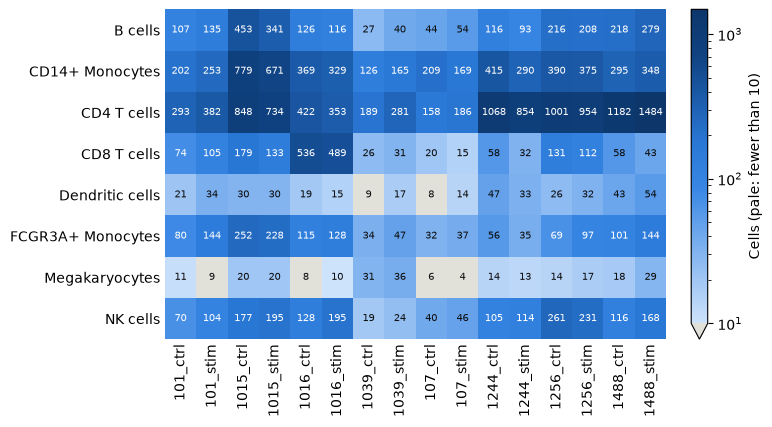

In [1]:
import matplotlib.pyplot as plt

import cytepool
from cytepool.design import Design
from cytepool.differential_expression import limma_trend, limma_voom
from cytepool.io import read_cube
from cytepool.plotting import (
    plot_cell_numbers,
    plot_md,
    plot_significant_genes,
    plot_volcano,
)

cube = read_cube("kang2018.cube.zarr")
print(f"CytePool {cytepool.__version__}")
print(cube)
plot_cell_numbers(cube)
plt.show()

A profile pooled from a handful of cells is noisy, so {api}`limma_voom` leaves the
profiles of fewer than 10 cells out of their cell type's fit (`min_cells=10`); they
are pale in the heatmap. Two samples of the dendritic cells and four of the
megakaryocytes are left out, and every other profile enters.

## A paired design

Every donor gives a control and a stimulated sample. The design `~ donor + condition`
compares each donor's two samples, so that the differences between donors do not count
as noise, and its coefficient `conditionstim` is the log2 fold change of the
stimulation. Name the levels of the condition: the first is the reference.
{api}`Design.check` looks for designs that cannot answer the question before anything
is fitted ([Designs, linear models and contrasts](../statistics/linear_models.md)).

In [2]:
design = Design(
    cube.samples,
    "~ donor + condition",
    levels={"condition": ["ctrl", "stim"]},
    contrasts={"stim_vs_ctrl": "conditionstim"},
)
print(design)
print(design.check())

Design: 16 samples x 9 columns, formula '~ donor + condition'
  columns: (Intercept), donor1015, donor1016, donor1039, donor107, donor1244,
           donor1256, donor1488, conditionstim
  contrasts: stim_vs_ctrl
Design check: 16 samples, 9 columns, rank 9, 7 residual degrees of freedom; no
              problems found.


## Test every cell type

{api}`limma_voom` runs limma-voom in each cell type in turn: it leaves out the profiles
with too few cells, keeps the genes with enough counts for the design, normalizes the
libraries by TMM, gives every observation a voom precision weight, fits the design to
every gene and moderates the contrast by empirical Bayes [@law2014; @ritchie2015]. The
figure counts the genes up and down at an adjusted p-value below 0.05 in each cell
type, the first figure to look at in a study of many cell types.

DifferentialExpressionResult (limma_voom): 8 groups, 8 fitted; 1 contrast:
    stim_vs_ctrl
  B cells: 16 samples, 2,768 features
  CD14+ Monocytes: 16 samples, 5,125 features
  CD4 T cells: 16 samples, 6,295 features
  CD8 T cells: 16 samples, 1,453 features
  Dendritic cells: 14 samples, 2,281 features
  FCGR3A+ Monocytes: 16 samples, 2,947 features
  Megakaryocytes: 12 samples, 704 features
  NK cells: 16 samples, 2,292 features


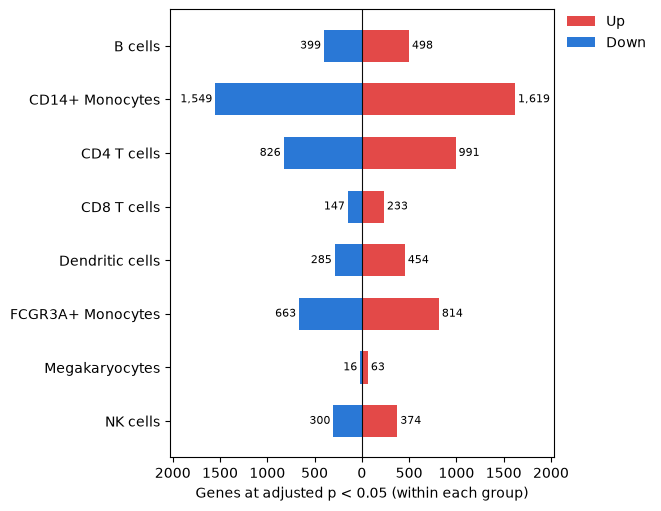

In [3]:
result = limma_voom(cube, design)
print(result)
plot_significant_genes(result)
plt.show()

A cell type left with too few samples to estimate a variance is not fitted, and both
the printed summary and the figure say so ([Designs, linear models and
contrasts](../statistics/linear_models.md#designs-that-cannot-answer-the-question) says
when); `result.summary` gives the
reason and `result.samples` lists every profile with the reason it was left out. Each fit keeps
the rows of the design for its own samples, so the megakaryocytes, which have no
profile of donor 107, are fitted without that donor's column.

## One cell type in detail

Each cell type and contrast has a table with the columns of limma's `topTable`
({api}`DifferentialExpressionResult.table`). The mean-difference plot shows the log2
fold changes against the average expression, and the volcano plot the p-values against
the fold changes, with the genes of the smallest p-values named.

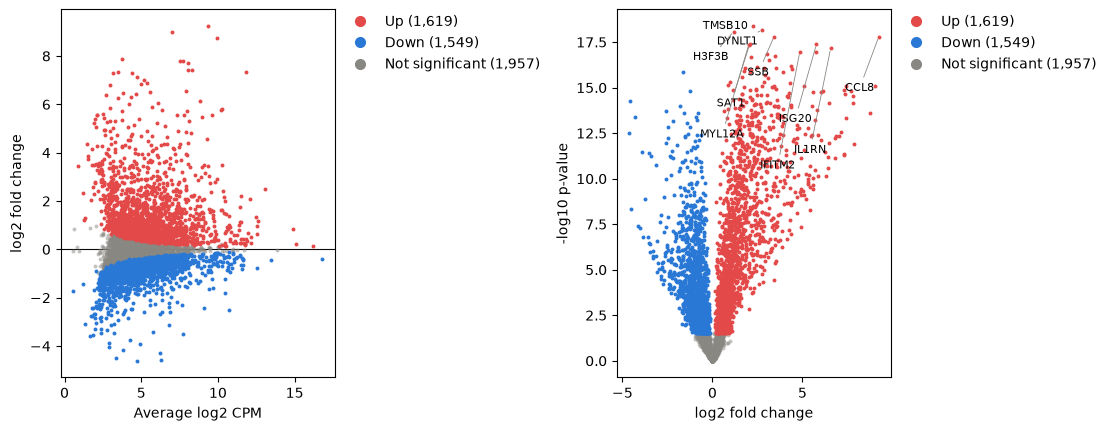

In [4]:
table = result.table("CD14+ Monocytes", "stim_vs_ctrl")
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
plot_md(table, ax=left)
plot_volcano(table, ax=right)
plt.show()

The table converts to a pandas DataFrame ({api}`Table.to_pandas`) for sorting and
export; here are the ten genes with the smallest p-values.

In [5]:
top = table.to_pandas().sort_values("p_value").head(10).set_index("symbol")
top[["log2_fold_change", "average_log2_cpm", "t", "adjusted_p_value"]]

,log2_fold_change,average_log2_cpm,t,adjusted_p_value
symbol,,,,
TMSB10,2.228256,11.474782,38.702966,1.455044e-15
DYNLT1,2.775521,9.811715,37.638832,1.455044e-15
H3F3B,1.177559,12.599981,37.213292,1.455044e-15
SSB,3.422422,8.193045,35.983010,1.660465e-15
CCL8,9.238620,9.334261,35.920825,1.660465e-15
SAT1,2.070418,12.110639,34.130852,2.787852e-15
ISG20,5.775101,10.180128,34.077674,2.787852e-15
MYL12A,2.019334,10.454437,34.018914,2.787852e-15
IL1RN,6.566429,7.950714,33.131986,4.001987e-15


## voom or trend

{api}`limma_trend` fits the log-CPM values without precision weights and lets the prior
variance follow the expression level. It suits libraries of similar sizes, within
about threefold of each other by the limma User's Guide ([Choosing a
method](../statistics/choosing_a_method.md)). A pseudobulk library grows with the
number of cells pooled, and the libraries of each cell type here differ far more:

B cells            largest library 14.5 times the smallest
CD14+ Monocytes    largest library  5.5 times the smallest
CD4 T cells        largest library  9.8 times the smallest
CD8 T cells        largest library 31.2 times the smallest
Dendritic cells    largest library  3.9 times the smallest
FCGR3A+ Monocytes  largest library  7.1 times the smallest
Megakaryocytes     largest library  8.5 times the smallest
NK cells           largest library 10.1 times the smallest


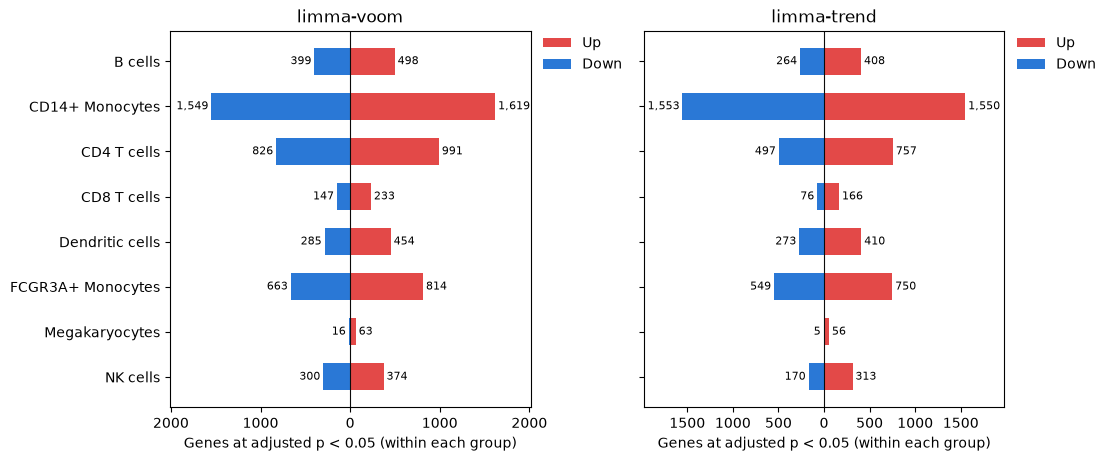

In [6]:
used = result.samples.filter(result.samples["used"])
for group in result.groups:
    sizes = used.filter(used["group_id"] == group)["library_size"]
    print(
        f"{group:<18} largest library {sizes.max() / sizes.min():4.1f} times the smallest"
    )

trend = limma_trend(cube, design)
figure, (left, right) = plt.subplots(
    1, 2, figsize=(11, 4.5), layout="constrained", sharey=True
)
plot_significant_genes(result, ax=left)
left.set_title("limma-voom")
plot_significant_genes(trend, ax=right)
right.set_title("limma-trend")
plt.show()

limma-trend calls fewer genes than limma-voom in every cell type, and the gap is
widest where the libraries differ most, as in the CD8 T cells; where they differ
least, as in the dendritic cells and the CD14+ monocytes, the two agree more closely.
voom's weights give the small libraries less say.

## Adjusting within or across cell types

The p-values of each cell type and contrast are adjusted over its own genes, as limma's
`topTable` adjusts them. `adjust_across_groups=True` adds a column adjusted over the
genes of every cell type for the same contrast, one family of tests for the study
([Multiple testing](../statistics/multiple_testing.md)).

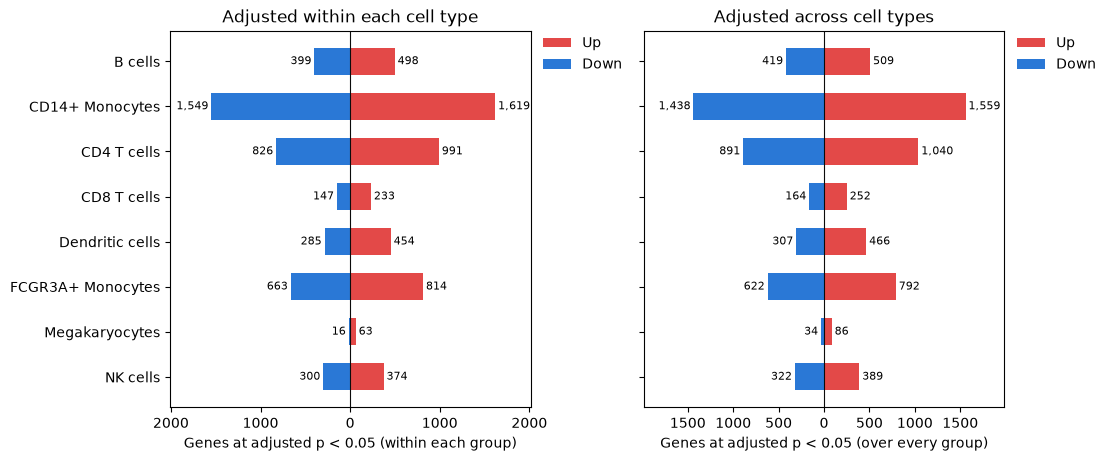

In [7]:
across = limma_voom(cube, design, adjust_across_groups=True)
figure, (left, right) = plt.subplots(
    1, 2, figsize=(11, 4.5), layout="constrained", sharey=True
)
plot_significant_genes(across, ax=left)
left.set_title("Adjusted within each cell type")
plot_significant_genes(across, across_groups=True, ax=right)
right.set_title("Adjusted across cell types")
plt.show()

Adjusting across cell types is not stricter for every cell type. The many small
p-values of the monocytes lower the adjusted p-values of the other cell types' genes,
which gain calls, while the monocytes, now adjusted with genes that respond less, lose
some.

## Choices

- **voom or trend.** {api}`limma_voom` is the default, and the safer choice when library
  sizes vary with the number of cells pooled; {api}`limma_trend` is faster and suits
  libraries of similar sizes.
- **Profiles with few cells or counts.** `min_cells` (10) and `min_counts` (0) decide
  which profiles enter each fit; raise them when small pools look noisy on an MDS plot,
  or keep every profile and weight it by its number of cells with
  `prior_weights="n_cells"` [@hoffman2026a]. `quality_weights=True` down-weights the
  samples that follow the model less closely instead. [Normalization, filtering and
  sample quality](normalization_and_quality.ipynb) shows both.
- **Within or across cell types.** Adjust within each cell type to rank its genes;
  adjust across cell types when the study's list of genes, of every cell type, is the
  result.
- **A variable of the donors.** The paired design cannot test a variable that is
  constant within each donor, such as sex or disease: [Repeated measures and
  donors](repeated_measures.ipynb) tests it with a random effect for the donor.
- **Other models.** edgeR's quasi-likelihood F-tests and DESeq2 run on one cell type's
  counts at a time ({api}`Cube.layer`), as on [bulk RNA-seq](bulk_rna_seq.ipynb).

The responding genes feed the next questions: which pathways and regulators they
belong to ([Gene sets and pathways](gene_sets.ipynb)) and which regulators are active
([Pathway and regulator activity](pathway_activity.ipynb)).